# Sleep Quality: Predicting Sleep Efficiency with a Mamdani FIS

Sleep efficiency is defined as

$$\text{SE}(\%) = \frac{\text{Total Sleep Time}}{\text{Time in Bed}} \times 100, \qquad \text{Time in Bed} = \text{Sleep Latency} + \text{TST} + \text{WASO}$$

The FIS uses the three direct determinants of this ratio that are available in the Whoop dataset, plus a personal baseline:

| Input | Role in the formula | Pearson *r* with `sleep_efficiency` |
|---|---|---|
| `sleep_hours` | Total Sleep Time (numerator) | +0.545 |
| `time_to_fall_asleep_min` | Sleep-onset latency (awake time in bed) | −0.325 |
| `wake_ups` | Fragmentation / wake after sleep onset | −0.328 |
| `personal_baseline` | The user's own typical efficiency (mean over **previous** nights) | +0.715 |

The earlier version used `hrv` and `day_strain` (r ≈ 0.017 and r ≈ 0.000). Those measure autonomic state and exertion, not time in bed, and gave R² < 0. The sleep-stage columns (light/REM/deep) add up to `sleep_hours`, so they would only add multicollinearity and enlarge the rule base (3³ = 27 → 3⁵ = 243 rules).

## Imports

In [1]:
import sys
import os
import pandas as pd
import numpy as np
from skfuzzy.control import Rule
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

sys.path.append(os.path.abspath(os.path.join('..', 'src')))

from preprocessor import clean_missing_values
from mamdani_engine import GenericMamdaniEngine
from evaluation import (evaluate_regression, plot_regression_results, plot_membership_functions, plot_control_surface, plot_data_distributions, plot_universe_percentiles)

## Data Preprocessing

In [2]:
# File paths
raw_path = '../data/raw/whoop_fitness_dataset_100k.csv'
processed_path = '../data/processed/whoop_clean.csv'

night_features = ['sleep_hours', 'time_to_fall_asleep_min', 'wake_ups']
input_features = night_features + ['personal_baseline']
target = 'sleep_efficiency'
# hrv / day_strain are kept only to reproduce the previous FIS as a baseline
baseline_features = ['hrv', 'day_strain']
raw_cols = ['user_id', 'date'] + night_features + baseline_features + [target]
selected_cols = raw_cols + ['personal_baseline']

# Rebuild the cached file if it is missing or was saved with other columns
cache_ok = os.path.exists(processed_path) and list(pd.read_csv(processed_path, nrows=0).columns) == selected_cols
if not cache_ok:
    print("Loading raw data and applying general preprocessing...")
    df_raw = pd.read_csv(raw_path)
    df_subset = df_raw[raw_cols].copy()
    df_clean = clean_missing_values(df_subset, subset_columns=raw_cols)

    # Personal baseline: the user's mean sleep efficiency over their PREVIOUS nights.
    # shift() excludes the current night, so the feature never sees the value being predicted.
    df_clean['date'] = pd.to_datetime(df_clean['date'])
    df_clean = df_clean.sort_values(['user_id', 'date']).reset_index(drop=True)
    df_clean['personal_baseline'] = (
        df_clean.groupby('user_id')[target]
        .transform(lambda s: s.shift().expanding().mean())
        .fillna(df_clean[target].mean())  # first night of a user: population mean
    )
    os.makedirs(os.path.dirname(processed_path), exist_ok=True)
    df_clean.to_csv(processed_path, index=False)
    print(f"Clean dataset saved to: {processed_path}")
else:
    print("Loading preprocessed dataset...")
    df_clean = pd.read_csv(processed_path)

print(f"Dataset shape: {df_clean.shape} | users: {df_clean['user_id'].nunique()}")
print('wake_ups value counts:', df_clean['wake_ups'].value_counts().sort_index().to_dict())

# Input conditioning: 3+ wake-ups are ~1% of nights and all mean "many",
# so wake_ups is clipped to [0, 2] to keep the universe focused on the data.
df_clean['wake_ups'] = df_clean['wake_ups'].clip(0, 2)

# Hold-out split: everything (universes, rule consequents) is calibrated on train only
df_train, df_test = train_test_split(df_clean, test_size=0.2, random_state=42)
print(f"Train: {len(df_train)} rows | Test: {len(df_test)} rows")
df_train.head()

Loading preprocessed dataset...
Dataset shape: (100000, 9) | users: 286
wake_ups value counts: {0: 72762, 1: 21687, 2: 4613, 3: 791, 4: 131, 5: 15, 7: 1}
Train: 80000 rows | Test: 20000 rows


,user_id,date,sleep_hours,time_to_fall_asleep_min,wake_ups,hrv,day_strain,sleep_efficiency,personal_baseline
75220,USER_00215,2023-01-19,8.02,5.0,0,53.8,10.44,90.5,89.994444
48955,USER_00140,2023-11-25,6.45,5.0,2,147.9,2.45,70.0,69.712195
44966,USER_00129,2023-03-30,6.50,5.0,0,60.5,15.09,86.6,80.090909
13568,USER_00039,2023-05-18,7.97,5.0,1,123.7,5.87,88.4,90.338686
92727,USER_00266,2023-01-04,7.03,5.2,0,58.8,11.35,75.3,86.200000


## Data Distribution Analysis & Universe Calibration

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
sleep_hours,80000.0,7.30,0.97,4.0,4.75,5.49,6.65,7.46,8.02,8.64,9.02,9.91
time_to_fall_asleep_min,80000.0,5.57,2.19,5.0,5.00,5.00,5.00,5.00,5.00,9.00,16.10,51.30
wake_ups,80000.0,0.33,0.57,0.0,0.00,0.00,0.00,0.00,1.00,2.00,2.00,2.00
personal_baseline,80000.0,82.90,7.41,50.0,68.39,69.47,79.42,80.82,89.91,90.46,91.18,100.00
sleep_efficiency,80000.0,82.90,10.20,50.0,54.30,63.50,76.50,85.00,90.50,96.60,100.00,100.00


Sleep hours universe: [4.0, 9.91]
Latency universe: [5.0, 51.3]  (share of nights at the 5-min floor: 85.7%)
Personal baseline percentiles: {0.05: 69.5, 0.25: 79.4, 0.5: 80.8, 0.75: 89.9, 0.95: 90.5}
Correlation personal_baseline vs sleep_efficiency: 0.715


--- Mean sleep efficiency by sleep hours (rows) x latency (columns) ---


time_to_fall_asleep_min,"(0, 5]","(5, 10]","(10, 60]"
sleep_hours,,,
"(0, 6]",74.5,69.0,65.1
"(6, 7]",79.1,73.1,68.6
"(7, 8]",86.2,78.2,72.9
"(8, 11]",89.2,82.8,76.6


--- Feature Distributions Analysis ---


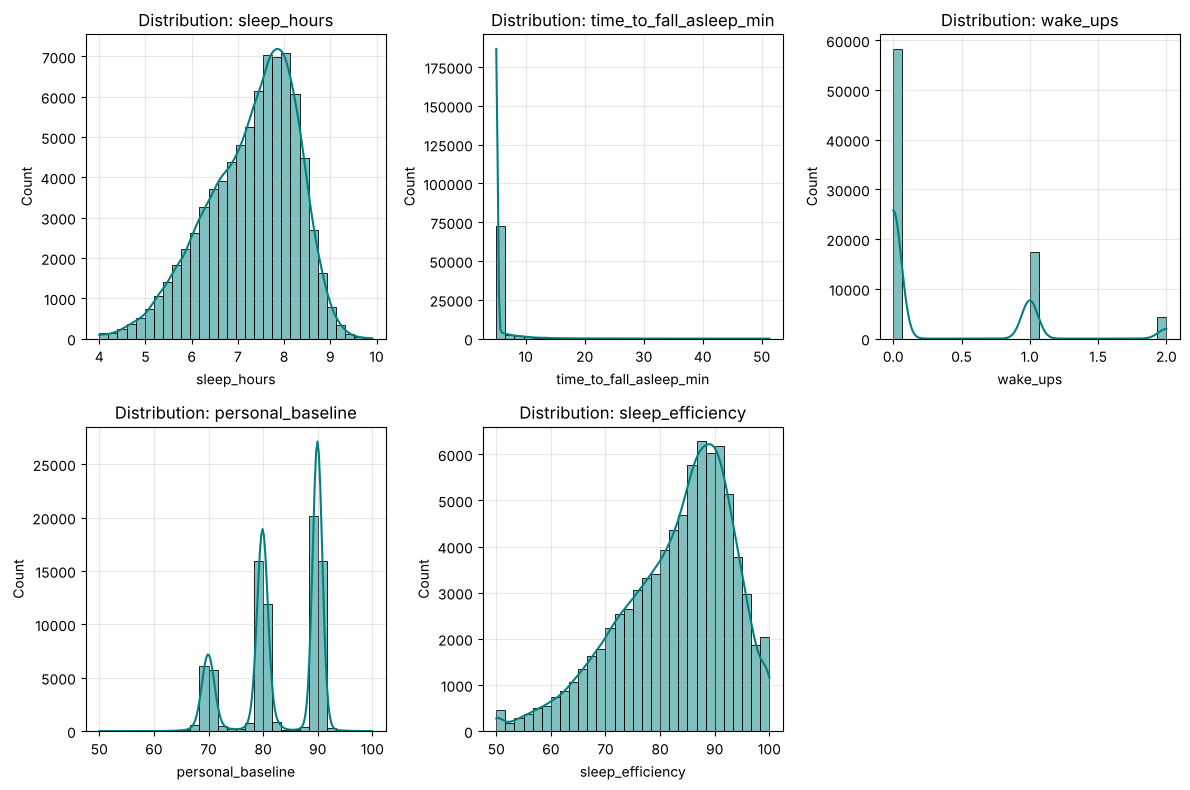

--- Target Consequent Percentile Calibration ---


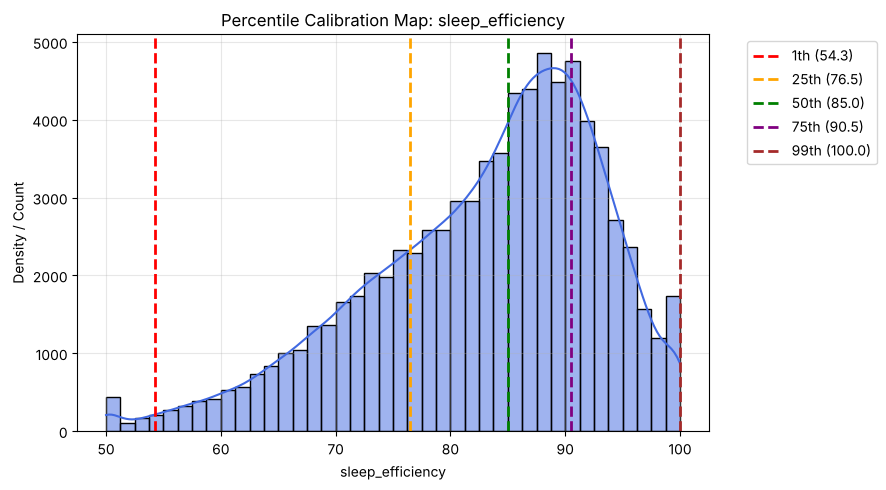

In [3]:
# Statistical bounds and percentiles from the training set
pct = [0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
display(df_train[input_features + [target]].describe(percentiles=pct).T.round(2))

sleep_min, sleep_max = float(df_train['sleep_hours'].min()), float(df_train['sleep_hours'].max())
lat_min, lat_max = float(df_train['time_to_fall_asleep_min'].min()), float(df_train['time_to_fall_asleep_min'].max())
eff_min, eff_max = 50.0, 100.0
print(f'Sleep hours universe: [{sleep_min}, {sleep_max}]')
print(f'Latency universe: [{lat_min}, {lat_max}]  (share of nights at the 5-min floor: '
      f"{(df_train['time_to_fall_asleep_min'] <= 5.0).mean():.1%})")
print('Personal baseline percentiles:', df_train['personal_baseline'].quantile([0.05, 0.25, 0.5, 0.75, 0.95]).round(1).to_dict())
print(f"Correlation personal_baseline vs {target}: {df_train[['personal_baseline', target]].corr().iloc[0, 1]:.3f}")

# Mean efficiency on a coarse grid: the shape the rule base has to reproduce
grid = df_train.groupby([
    pd.cut(df_train['sleep_hours'], [0, 6, 7, 8, 11]),
    pd.cut(df_train['time_to_fall_asleep_min'], [0, 5, 10, 60]),
], observed=True)[target].mean().unstack().round(1)
print('--- Mean sleep efficiency by sleep hours (rows) x latency (columns) ---')
display(grid)

print('--- Feature Distributions Analysis ---')
plot_data_distributions(df_train, columns=input_features + [target])

print('--- Target Consequent Percentile Calibration ---')
plot_universe_percentiles(df_train, target_col=target, percentiles=[0.01, 0.25, 0.50, 0.75, 0.99])

## Mamdani FIS Configuration & Membership Functions

- **`sleep_hours`**: *short* below ~6 h, *adequate* around 7 h, *long* from ~8 h (5th / 50th / 95th percentiles: 5.5 / 7.5 / 8.6 h).
- **`time_to_fall_asleep_min`**: more than 75% of nights sit exactly at the 5-min floor, so *short* is a narrow shoulder at 5–5.5 min. *Moderate* peaks at 9 min (the 95th percentile) and *long* covers the tail.
- **`wake_ups`**: integer counts 0 / 1 / 2+ map to *few* / *medium* / *many*.
- **`personal_baseline`**: users fall into three groups of typical efficiency (≈70 %, ≈80 %, ≈90 %, see the histogram above), which become *low* / *medium* / *high*.
- **`sleep_efficiency`**: five triangular terms centered on the efficiency levels observed in the data (≈64, 69, 76, 83, 89 %). Wide shoulders reaching 50 and 100 would pull the centroid toward the middle of the range.

Output term centers: {'poor': 62.7, 'below_average': 69.0, 'average': 76.0, 'good': 83.0, 'excellent': 89.0}
--- Generare Grafice Funcții de Apartenență (Antecedente) ---


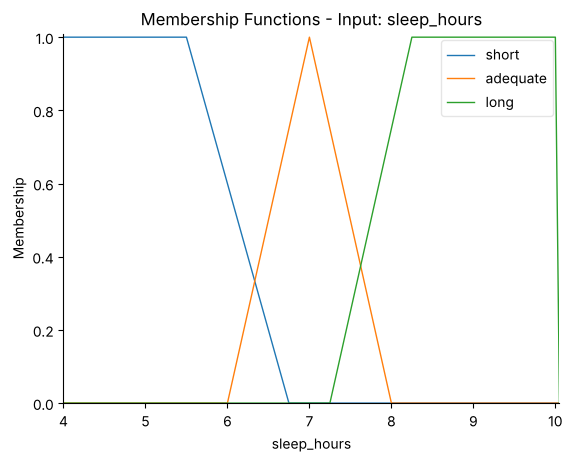

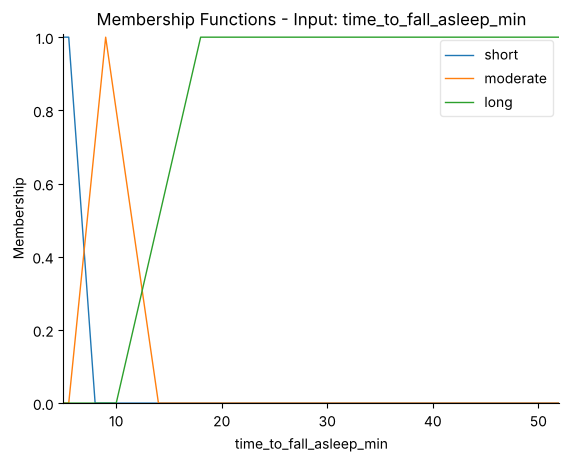

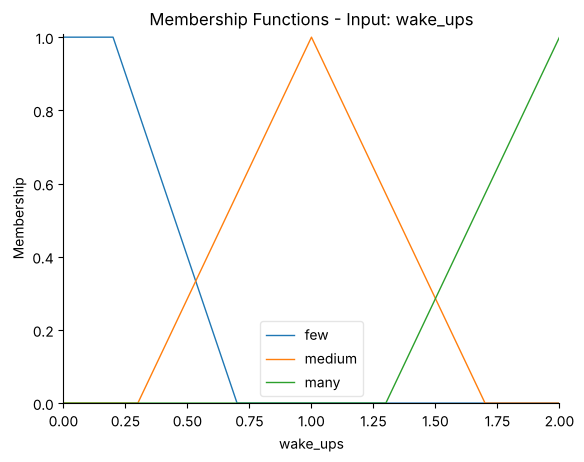

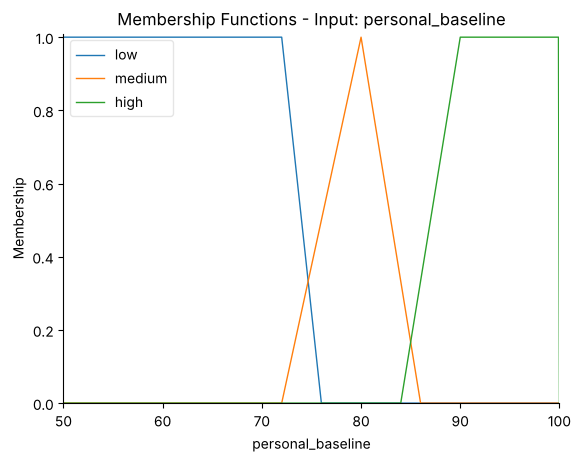

--- Generare Grafice Funcții de Apartenență (Consecvent) ---


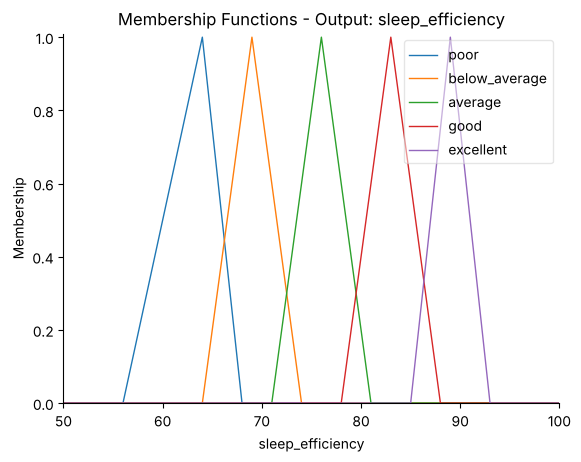

In [4]:
def build_fis(with_baseline=True, defuzzify_method='centroid'):
    fis = GenericMamdaniEngine()
    fis.add_antecedent(
        'sleep_hours',
        np.arange(4.0, 10.0 + 0.05, 0.05),
        {
            'short': [4.0, 4.0, 5.5, 6.75],
            'adequate': [6.0, 7.0, 8.0],
            'long': [7.25, 8.25, 10.0, 10.0]
        }
    )
    fis.add_antecedent(
        'time_to_fall_asleep_min',
        np.arange(5.0, 52.0 + 0.5, 0.5),
        {
            'short': [5.0, 5.0, 5.5, 8.0],
            'moderate': [5.5, 9.0, 14.0],
            'long': [10.0, 18.0, 52.0, 52.0]
        }
    )
    fis.add_antecedent(
        'wake_ups',
        np.arange(0.0, 2.0 + 0.05, 0.05),
        {
            'few': [0.0, 0.0, 0.2, 0.7],
            'medium': [0.3, 1.0, 1.7],
            'many': [1.3, 2.0, 2.0, 2.0]
        }
    )
    if with_baseline:
        fis.add_antecedent(
            'personal_baseline',
            np.arange(50.0, 100.0 + 0.1, 0.1),
            {
                'low': [50.0, 50.0, 72.0, 76.0],
                'medium': [72.0, 80.0, 86.0],
                'high': [84.0, 90.0, 100.0, 100.0]
            }
        )
    fis.add_consequent(
        'sleep_efficiency',
        np.arange(eff_min, eff_max + 0.25, 0.25),
        {
            'poor': [56.0, 64.0, 68.0],
            'below_average': [64.0, 69.0, 74.0],
            'average': [71.0, 76.0, 81.0],
            'good': [78.0, 83.0, 88.0],
            'excellent': [85.0, 89.0, 93.0]
        },
        defuzzify_method=defuzzify_method
    )
    return fis

fis = build_fis()
print('Output term centers:', {k: round(v, 1) for k, v in fis.term_centers(target).items()})
plot_membership_functions(fis)

## IF-THEN Rules Definition

### Expert rule base (27 rules, night inputs only)
A hand-written reference built from sleep physiology alone. Starting level from sleep hours (long → *excellent*, adequate → *good*, short → *below_average*). Each step up in latency or in wake-ups lowers the outcome by one level, never below *poor*.

In [5]:
levels = ['poor', 'below_average', 'average', 'good', 'excellent']
sleep_base = {'short': 1, 'adequate': 3, 'long': 4}
latency_penalty = {'short': 0, 'moderate': 1, 'long': 2}
wake_penalty = {'few': 0, 'medium': 1, 'many': 2}

# Rule matrix keyed wake_ups -> sleep_hours -> latency
rule_matrix = {
    wake: {
        sleep: {lat: levels[max(0, sleep_base[sleep] - latency_penalty[lat] - wake_penalty[wake])]
                for lat in latency_penalty}
        for sleep in sleep_base
    }
    for wake in wake_penalty
}

table_data = []
for wake_level, sleep_dict in rule_matrix.items():
    for sleep_level, lat_dict in sleep_dict.items():
        for lat_level, outcome in lat_dict.items():
            table_data.append({
                'sleep_hours': sleep_level,
                'time_to_fall_asleep_min': lat_level,
                'wake_ups': wake_level,
                target: outcome,
            })
expert_table = pd.DataFrame(table_data)
expert_rules = {tuple(r[c] for c in night_features): r[target] for _, r in expert_table.iterrows()}

pd.set_option('display.max_rows', None)
expert_table.index = expert_table.index + 1
expert_table.index.name = 'Rule'
expert_table

,sleep_hours,time_to_fall_asleep_min,wake_ups,sleep_efficiency
Rule,,,,
1,short,short,few,below_average
2,short,moderate,few,poor
3,short,long,few,poor
4,adequate,short,few,good
5,adequate,moderate,few,average
6,adequate,long,few,below_average
7,long,short,few,excellent
8,long,moderate,few,good
9,long,long,few,average


### Data-driven rule base with personal baseline (Wang–Mendel style)
With four inputs there are 3⁴ = 81 antecedent combinations. For each of them, the engine computes the firing strength (AND = min) on every **training** row. It takes the firing-weighted mean of `sleep_efficiency` and assigns the output term whose center is closest to that mean. Combinations that (almost) never occur in the data (sum of firing strengths < 5, e.g. a *high*-baseline user with long latency and many wake-ups) are left out of the rule base. The rules stay readable IF-THEN statements, but each consequent is now backed by data.

In [6]:
learned_table = fis.learn_rule_consequents(df_train, input_features, target, min_support=5.0)
learned_table = learned_table[learned_table['source'] == 'data'].drop(columns='source').reset_index(drop=True)
learned_table.index = learned_table.index + 1
learned_table.index.name = 'Rule'
display(learned_table.round(1))
print(f"{len(learned_table)} of 81 combinations are supported by the data")

# Rule-base view: consequent per (sleep_hours, latency) for each baseline group, with few wake-ups
for pb in ['low', 'medium', 'high']:
    view = learned_table[(learned_table['personal_baseline'] == pb) & (learned_table['wake_ups'] == 'few')]
    print(f"personal_baseline = {pb}, wake_ups = few")
    display(view.pivot(index='sleep_hours', columns='time_to_fall_asleep_min', values=target)
            .reindex(index=['short', 'adequate', 'long'], columns=['short', 'moderate', 'long']))

rules = fis.rules_from_table(learned_table, input_features, target)
fis.build_system(rules)
print(f"Mamdani control system successfully built with {len(rules)} rules!")

,sleep_hours,time_to_fall_asleep_min,wake_ups,personal_baseline,support,weighted_mean,sleep_efficiency
Rule,,,,,,,
1,short,short,few,low,3365.3,73.1,average
2,short,short,few,medium,2460.0,81.6,good
3,short,short,few,high,32.8,88.3,excellent
4,short,short,medium,low,1766.0,69.7,below_average
5,short,short,medium,medium,900.5,78.2,average
6,short,short,medium,high,6.7,83.3,good
7,short,short,many,low,662.4,66.3,below_average
8,short,short,many,medium,243.5,75.3,average
9,short,moderate,few,low,525.3,68.0,below_average


70 of 81 combinations are supported by the data
personal_baseline = low, wake_ups = few


time_to_fall_asleep_min,short,moderate,long
sleep_hours,,,
short,average,below_average,poor
adequate,average,below_average,poor
long,average,below_average,below_average


personal_baseline = medium, wake_ups = few


time_to_fall_asleep_min,short,moderate,long
sleep_hours,,,
short,good,average,average
adequate,good,average,average
long,good,average,below_average


personal_baseline = high, wake_ups = few


time_to_fall_asleep_min,short,moderate,long
sleep_hours,,,
short,excellent,NaN,NaN
adequate,excellent,good,good
long,excellent,good,good


Mamdani control system successfully built with 70 rules!


## Running Inference on the Held-out Test Set

In [7]:
# Random i.i.d. sample of the held-out test set (scikit-fuzzy runs row by row)
df_sample = df_test.sample(2000, random_state=42).copy()
y_true = df_sample[target].values

print("Running fuzzy inference on held-out data...")
y_pred = fis.predict_dataset(df_sample, input_features)
print(f"Inference complete for {len(y_pred)} samples ({fis.fallback_count} fallback predictions with no rule fired).")

Running fuzzy inference on held-out data...


Inference complete for 2000 samples (0 fallback predictions with no rule fired).


## Evaluation and Visualization

--- Quantitative Error Metrics Table (held-out test sample) ---


,Metric,Value
0,MAE (Mean Absolute Error),5.316242
1,MSE (Mean Squared Error),48.133224
2,RMSE (Root Mean Squared Error),6.937811
3,R2 Score,0.544244


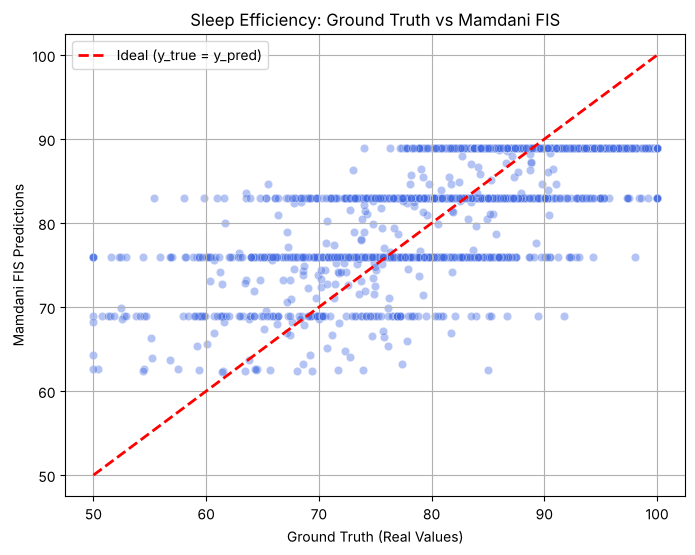

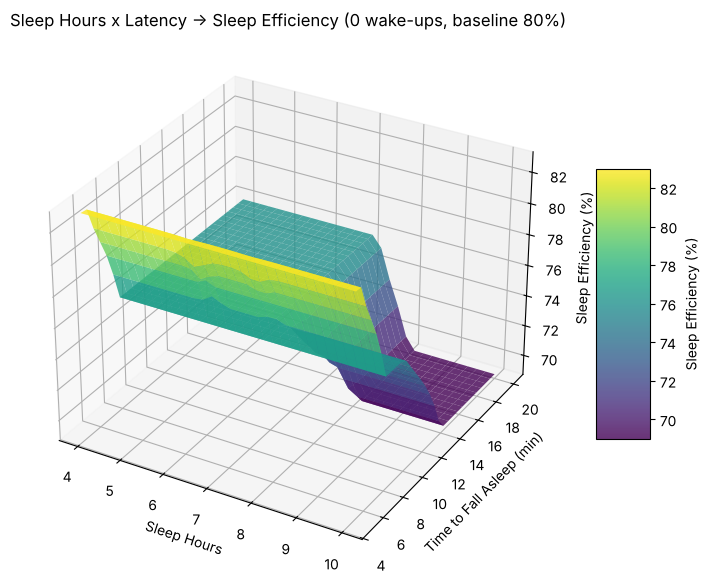

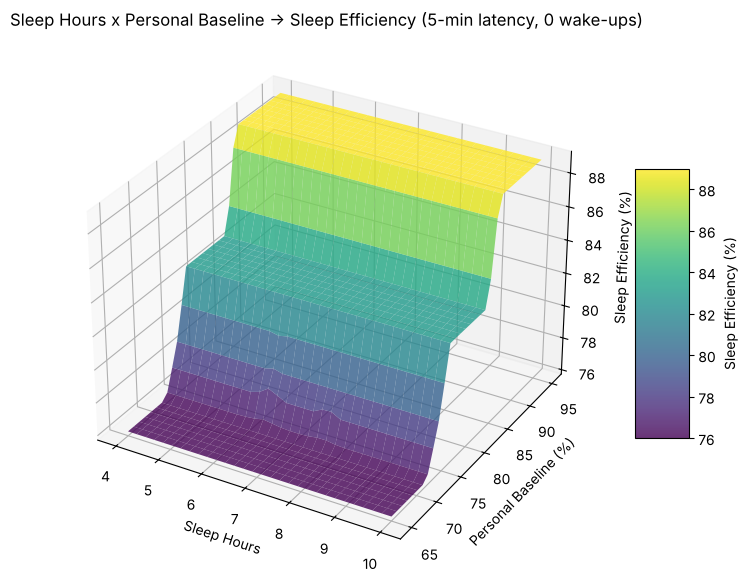

In [8]:
# 1. Quantitative Error Table
metrics_df = evaluate_regression(y_true, y_pred)
print("--- Quantitative Error Metrics Table (held-out test sample) ---")
display(metrics_df)

# 2. Regression Scatter Plot (Real vs Predicted)
plot_regression_results(y_true, y_pred, title='Sleep Efficiency: Ground Truth vs Mamdani FIS')

# 3. 3D Control Surface Plot (no wake-ups)
plot_control_surface(
    fis.simulation, 'sleep_hours', 'time_to_fall_asleep_min', target,
    x_range=(4.0, 10.0), y_range=(5.0, 20.0),
    fixed_inputs={'wake_ups': 0.0, 'personal_baseline': 80.0},
    labels=('Sleep Hours', 'Time to Fall Asleep (min)', 'Sleep Efficiency (%)'),
    title='Sleep Hours x Latency -> Sleep Efficiency (0 wake-ups, baseline 80%)',
)

# 4. 3D Control Surface Plot: tonight's sleep vs the user's personal baseline
plot_control_surface(
    fis.simulation, 'sleep_hours', 'personal_baseline', target,
    x_range=(4.0, 10.0), y_range=(65.0, 95.0),
    fixed_inputs={'wake_ups': 0.0, 'time_to_fall_asleep_min': 5.0},
    labels=('Sleep Hours', 'Personal Baseline (%)', 'Sleep Efficiency (%)'),
    title='Sleep Hours x Personal Baseline -> Sleep Efficiency (5-min latency, 0 wake-ups)',
)

## Baseline Comparison

All models are scored on the same held-out sample:
- **Mean predictor**: always predicts the training mean (R² = 0 by definition).
- **Linear regression**: fitted on the three night inputs, and on all four inputs.
- **Previous FIS**: the HRV / day strain / wake-ups system from the earlier version.
- **Expert FIS (3 inputs)** and **data-driven FIS (3 inputs)**: night inputs only, with the hand-written and the learned rule base.
- **Data-driven FIS (4 inputs)**: the final model, with the personal baseline (centroid and bisector defuzzification).
- **Data-driven FIS without `sleep_hours`**: latency, wake-ups and personal baseline only.
- **Binned lookup table (3 inputs)**: mean efficiency in fine bins of the night inputs. This approximates the best any model can do without knowing who the user is.

In [9]:
def scores(name, pred):
    m = evaluate_regression(y_true, pred).set_index('Metric')['Value']
    return {'Model': name, 'MAE': m.iloc[0], 'RMSE': m.iloc[2], 'R2': m.iloc[3]}

results = [scores('Mean predictor', np.full(len(y_true), df_train[target].mean()))]

lin3 = LinearRegression().fit(df_train[night_features], df_train[target])
results.append(scores('Linear regression (3 night inputs)', lin3.predict(df_sample[night_features])))
lin4 = LinearRegression().fit(df_train[input_features], df_train[target])
results.append(scores('Linear regression (4 inputs)', lin4.predict(df_sample[input_features])))

# Previous FIS: hrv / day_strain / wake_ups with the earlier membership functions and rules
old = GenericMamdaniEngine()
old.add_antecedent('hrv', np.arange(20, 151, 1), {'low': [20.0, 20.0, 45.0, 65.0], 'medium': [45.0, 75.0, 105.0], 'high': [85.0, 115.0, 150.0, 150.0]})
old.add_antecedent('day_strain', np.arange(0, 21.5, 0.5), {'low': [0.0, 0.0, 5.0, 8.0], 'medium': [6.0, 11.0, 15.0], 'high': [13.0, 17.0, 21.0, 21.0]})
old.add_antecedent('wake_ups', np.arange(0, 8, 0.1), {'few': [0.0, 0.0, 0.2, 0.7], 'medium': [0.4, 1.0, 1.6], 'many': [1.3, 2.0, 7.0, 7.0]})
old.add_consequent('sleep_efficiency', np.arange(50, 101, 0.5), {'poor': [50.0, 50.0, 65.0, 70.0], 'below_average': [68.0, 73.0, 77.0], 'average': [74.0, 78.0, 82.0], 'good': [80.0, 83.5, 87.0], 'excellent': [85.0, 88.0, 95.0, 95.0]})
old_matrix = {  # wake -> hrv -> strain
    'few':    {'low': ['below_average', 'average', 'below_average'], 'medium': ['average', 'good', 'average'], 'high': ['good', 'excellent', 'good']},
    'medium': {'low': ['poor', 'below_average', 'poor'], 'medium': ['below_average', 'average', 'below_average'], 'high': ['average', 'good', 'average']},
    'many':   {'low': ['poor', 'poor', 'poor'], 'medium': ['poor', 'below_average', 'poor'], 'high': ['below_average', 'below_average', 'poor']},
}
old_table = pd.DataFrame([
    {'hrv': h, 'day_strain': s, 'wake_ups': w, target: out}
    for w, hd in old_matrix.items() for h, outs in hd.items() for s, out in zip(['low', 'medium', 'high'], outs)
])
old_inputs = ['hrv', 'day_strain', 'wake_ups']
old.build_system(old.rules_from_table(old_table, old_inputs, target))
results.append(scores('Previous FIS (hrv, day_strain, wake_ups)', old.predict_dataset(df_sample, old_inputs)))

expert_fis = build_fis(with_baseline=False)
expert_fis.build_system(expert_fis.rules_from_table(expert_table, night_features, target))
results.append(scores('Expert FIS (3 night inputs)', expert_fis.predict_dataset(df_sample, night_features)))

fis3 = build_fis(with_baseline=False)
table3 = fis3.learn_rule_consequents(df_train, night_features, target, min_support=5.0, default_rules=expert_rules)
fis3.build_system(fis3.rules_from_table(table3, night_features, target))
results.append(scores('Data-driven FIS (3 night inputs)', fis3.predict_dataset(df_sample, night_features)))

results.append(scores('Data-driven FIS (4 inputs), centroid', y_pred))
bis_fis = build_fis(defuzzify_method='bisector')
bis_fis.build_system(bis_fis.rules_from_table(learned_table, input_features, target))
results.append(scores('Data-driven FIS (4 inputs), bisector', bis_fis.predict_dataset(df_sample, input_features)))

# Compact variant without sleep_hours (see the within-user analysis below)
compact_inputs = ['time_to_fall_asleep_min', 'wake_ups', 'personal_baseline']
fis_c = build_fis()
table_c = fis_c.learn_rule_consequents(df_train, compact_inputs, target, min_support=5.0)
rules_c = fis_c.rules_from_table(table_c, compact_inputs, target)
fis_c.build_system(rules_c)
results.append(scores(f'Data-driven FIS without sleep_hours ({len(rules_c)} rules)', fis_c.predict_dataset(df_sample, compact_inputs)))

# Approximate ceiling for these inputs: mean efficiency in fine bins, fitted on train
bins = lambda d: pd.DataFrame({
    's': pd.cut(d['sleep_hours'], np.linspace(4, 10, 21), include_lowest=True),
    'l': pd.cut(d['time_to_fall_asleep_min'], [0, 5.01, 7, 9, 12, 16, 60]),
    'w': d['wake_ups'],
})
lookup = df_train[[target]].join(bins(df_train)).groupby(['s', 'l', 'w'], observed=True)[target].mean()
ceiling_pred = bins(df_sample).join(lookup, on=['s', 'l', 'w'])[target].fillna(df_train[target].mean()).values
results.append(scores('Binned lookup table (3 night inputs)', ceiling_pred))

comparison = pd.DataFrame(results).set_index('Model')
display(comparison.round(3))

,MAE,RMSE,R2
Model,,,
Mean predictor,8.296,10.280,-0.001
Linear regression (3 night inputs),6.131,7.936,0.404
Linear regression (4 inputs),5.209,6.781,0.565
"Previous FIS (hrv, day_strain, wake_ups)",10.093,12.251,-0.421
Expert FIS (3 night inputs),6.750,8.574,0.304
Data-driven FIS (3 night inputs),6.283,8.022,0.391
"Data-driven FIS (4 inputs), centroid",5.316,6.938,0.544
"Data-driven FIS (4 inputs), bisector",5.324,6.948,0.543
Data-driven FIS without sleep_hours (26 rules),5.338,6.961,0.541


## Why does `sleep_hours` stop mattering once the baseline is known?
The second control surface is flat along sleep hours. The correlations below explain it: **within the same user, sleep hours have no relationship with efficiency**. The overall +0.55 correlation is a between-user effect: in this dataset, people who habitually sleep long also belong to the high-efficiency profile. Once `personal_baseline` identifies the profile, only latency and wake-ups still explain night-to-night changes.

In [10]:
rows = []
for col in night_features:
    within_x = df_clean[col] - df_clean.groupby('user_id')[col].transform('mean')
    within_y = df_clean[target] - df_clean.groupby('user_id')[target].transform('mean')
    rows.append({
        'Feature': col,
        'Overall r': df_clean[[col, target]].corr().iloc[0, 1],
        'Within-user r': np.corrcoef(within_x, within_y)[0, 1],
    })
display(pd.DataFrame(rows).set_index('Feature').round(3))

groups = pd.cut(df_clean['personal_baseline'], [0, 75, 85, 101], labels=['low', 'medium', 'high'])
print('Mean sleep efficiency by baseline group (rows) and sleep hours (columns):')
display(df_clean.groupby([groups, pd.cut(df_clean['sleep_hours'], [0, 6, 7, 8, 11])], observed=True)[target]
        .mean().unstack().round(1))

,Overall r,Within-user r
Feature,,
sleep_hours,0.545,-0.005
time_to_fall_asleep_min,-0.325,-0.231
wake_ups,-0.327,-0.233


Mean sleep efficiency by baseline group (rows) and sleep hours (columns):


sleep_hours,"(0, 6]","(6, 7]","(7, 8]","(8, 11]"
personal_baseline,,,,
low,70.1,69.8,70.1,71.3
medium,79.5,79.9,80.0,80.0
high,79.3,89.6,89.9,89.9


## Conclusions

On the held-out test sample (2,000 nights not used for calibration):

| Model | R² | MAE |
|---|---|---|
| Previous FIS (hrv, day_strain, wake_ups) | −0.42 | 10.09 |
| Expert FIS (3 night inputs) | 0.30 | 6.75 |
| Data-driven FIS (3 night inputs) | 0.39 | 6.28 |
| **Data-driven FIS + personal baseline (4 inputs, 70 rules)** | **0.54** | **5.32** |
| Data-driven FIS without `sleep_hours` (26 rules) | 0.54 | 5.34 |
| Linear regression (4 inputs) | 0.57 | 5.21 |

- **Choosing the right inputs matters most.** Using the components of the sleep-efficiency formula instead of HRV / strain lifts R² from below zero to 0.30, even with hand-written rules.
- **Learning rule consequents from data** adds about 0.09 R² while keeping readable IF-THEN rules.
- **Personalisation is the largest single gain.** Knowing the user's typical efficiency from their previous nights (causal, so the night being predicted is never seen) lifts R² from 0.39 to 0.54 and lowers MAE from 6.3 to 5.3 points. With only the three night inputs, no model can exceed about 0.43.
- **`sleep_hours` acts as a proxy for user type.** Its within-user correlation with efficiency is about 0. Once the baseline is known, a 26-rule FIS on latency, wake-ups and baseline performs as well as the 70-rule one. In this dataset, night-to-night variation is driven by sleep latency and awakenings.
- The FIS is within 0.02 R² of linear regression on the same inputs, while staying fully interpretable. Centroid and bisector defuzzification perform the same; centroid is kept.
- The predictions still form bands, because 86 % of nights sit at the 5-minute latency floor and wake-ups are whole numbers, so most nights fire a single dominant rule.